In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
df = pd.read_csv("House_Prices.csv")

df.head()

,House,Size,Bedrooms,Distance,Price
0,1,108,2,13,$103930.26
1,2,87,2,5,154929.76
2,3,NaN,3,9,224271.87
3,4,ERROR,???,NaN,INVALID
4,5,197,6,3,366822.34


In [ ]:
# Replace empty strings with NaN
df.replace("", np.nan, inplace=True)

# Remove currency symbols from Price
df["Price"] = df["Price"].astype(str).str.replace("$", "", regex=False)

# Convert all columns to numeric
for col in ["Price", "Size", "Bedrooms", "Distance"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove corrupted rows
df.dropna(inplace=True)

# Reset index
df.reset_index(drop=True, inplace=True)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1034 entries, 0 to 1033
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   House     1034 non-null   int64  
 1   Size      1034 non-null   float64
 2   Bedrooms  1034 non-null   float64
 3   Distance  1034 non-null   float64
 4   Price     1034 non-null   float64
dtypes: float64(4), int64(1)
memory usage: 40.5 KB


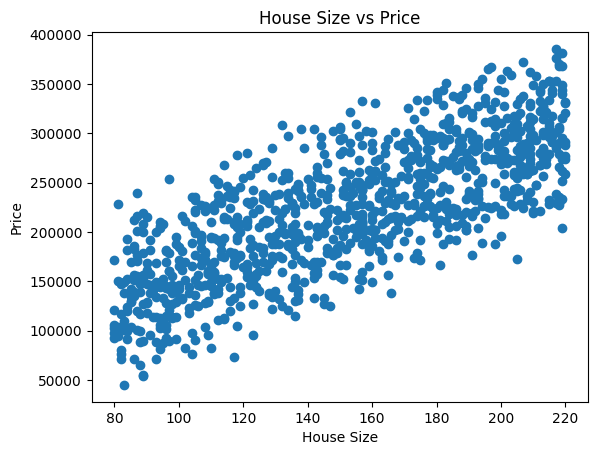

In [4]:
plt.scatter(df["Size"], df["Price"])
plt.xlabel("House Size")
plt.ylabel("Price")
plt.title("House Size vs Price")
plt.show()

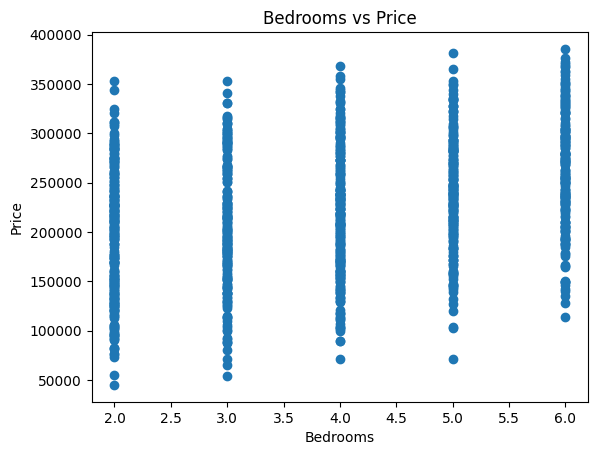

In [9]:
plt.scatter(df["Bedrooms"], df["Price"])
plt.xlabel("Bedrooms")
plt.ylabel("Price")
plt.title("Bedrooms vs Price")
plt.show()

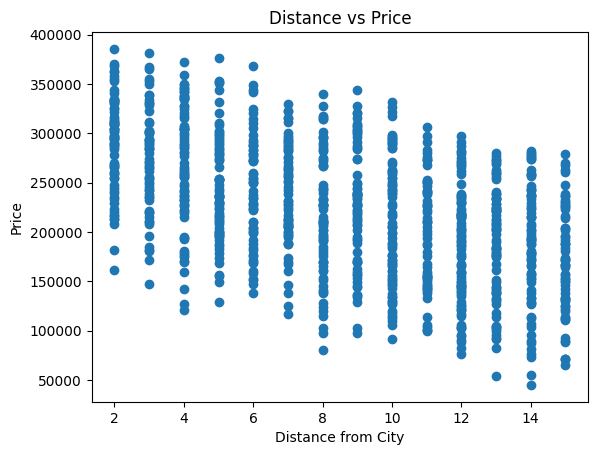

In [6]:
plt.scatter(df["Distance"], df["Price"])
plt.xlabel("Distance from City")
plt.ylabel("Price")
plt.title("Distance vs Price")
plt.show()

In [10]:
X = df[["Size","Bedrooms","Distance"]]
y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [11]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [12]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Lasso Regression": Lasso(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest": RandomForestRegressor(),
    "SVR": SVR(),
    "KNN": KNeighborsRegressor()
}

results = []
trained_models = {}

for name, model in models.items():

    if name in ["SVR", "KNN"]:
        model.fit(X_train_scaled, y_train)
        preds = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        preds = model.predict(X_test)

    mae = mean_absolute_error(y_test, preds)
    mse = mean_squared_error(y_test, preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, preds)

    results.append([name, mae, mse, rmse, r2])
    trained_models[name] = model

results_df = pd.DataFrame(results, columns=["Model","MAE","MSE","RMSE","R2"])

results_df

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,12490.247973,2.516270e+08,15862.753959,0.936620
1,Ridge Regression,12489.817548,2.516413e+08,15863.206657,0.936617
2,Lasso Regression,12490.228834,2.516279e+08,15862.783900,0.936620
3,Decision Tree,20098.747899,6.537161e+08,25567.872353,0.835342
4,Random Forest,15063.373990,3.570996e+08,18897.079924,0.910054
5,SVR,51831.948032,4.023405e+09,63430.314242,-0.013415
6,KNN,13897.996715,3.092183e+08,17584.604532,0.922114


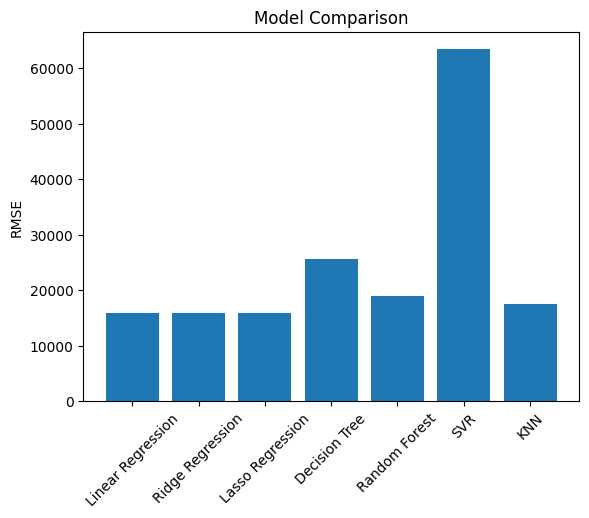

In [13]:
plt.bar(results_df["Model"], results_df["RMSE"])
plt.xticks(rotation=45)
plt.ylabel("RMSE")
plt.title("Model Comparison")
plt.show()

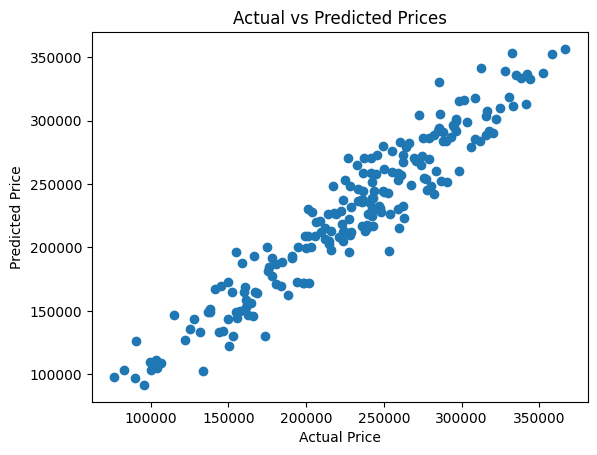

In [14]:
rf = trained_models["Random Forest"]

predictions = rf.predict(X_test)

plt.scatter(y_test, predictions)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Prices")
plt.show()

In [15]:
house = pd.DataFrame([[165,4,6]], columns=["Size","Bedrooms","Distance"])

prediction = rf.predict(house)

print("Predicted Price:", prediction[0])

Predicted Price: 263268.2565000002


# Task
Conclude the Multiple Linear Regression analysis by extracting and displaying the regression equation with its coefficients and intercept, interpreting the meaning of each coefficient, and summarizing the model's performance using MAE, MSE, RMSE, and R2 values from the `results_df`.

## Extract Linear Regression Coefficients and Intercept

### Subtask:
Retrieve the coefficients and intercept from the trained Linear Regression model to formulate the regression equation.


**Reasoning**:
To extract the coefficients and intercept from the trained Linear Regression model, I need to access the model from the `trained_models` dictionary and then retrieve its `coef_` and `intercept_` attributes.



In [20]:
linear_regression_model = trained_models["Linear Regression"]
coefficients = linear_regression_model.coef_
intercept = linear_regression_model.intercept_

print("Linear Regression Coefficients:", coefficients)
print("Linear Regression Intercept:", intercept)

Linear Regression Coefficients: [ 1220.86015016 15279.81179774 -8246.72911785]
Linear Regression Intercept: 47112.12730955702


## Display Regression Equation

### Subtask:
Construct and display the multiple linear regression equation using the extracted coefficients and intercept, clearly labeling the independent variables (Size, Bedrooms, Distance) and the dependent variable (Price).


**Reasoning**:
I need to construct and display the multiple linear regression equation using the extracted coefficients and intercept, along with the feature names.



In [17]:
feature_names = X.columns.tolist()

equation = f"Price = {intercept:.2f}"
for i, coeff in enumerate(coefficients):
    equation += f" + ({coeff:.2f} * {feature_names[i]})"

print("Multiple Linear Regression Equation:", equation)

Multiple Linear Regression Equation: Price = 47112.13 + (1220.86 * Size) + (15279.81 * Bedrooms) + (-8246.73 * Distance)


## Interpret Regression Coefficients

### Subtask:
Provide a clear interpretation of each coefficient in the regression equation, explaining its impact on the predicted house price while holding other variables constant. Discuss the meaning of the intercept.


```markdown
## Interpretation of Regression Coefficients and Intercept

The multiple linear regression equation is: **Price = 47112.13 + (1220.86 * Size) + (15279.81 * Bedrooms) + (-8246.73 * Distance)**

### Intercept: 47112.13
The intercept represents the predicted house price when all independent variables (Size, Bedrooms, and Distance) are zero. In this context, a house with zero size, zero bedrooms, and zero distance from the city is predicted to cost $47,112.13. While this might not be physically meaningful in a real-world scenario (as a house cannot have zero size or bedrooms), it serves as a baseline value for the model's predictions.

### Coefficient for Size: 1220.86
For every one-unit increase in 'Size' (e.g., one square foot), holding 'Bedrooms' and 'Distance' constant, the predicted 'Price' of the house increases by approximately $1,220.86.

### Coefficient for Bedrooms: 15279.81
For every one-unit increase in 'Bedrooms' (e.g., one additional bedroom), holding 'Size' and 'Distance' constant, the predicted 'Price' of the house increases by approximately $15,279.81.

### Coefficient for Distance: -8246.73
For every one-unit increase in 'Distance' from the city, holding 'Size' and 'Bedrooms' constant, the predicted 'Price' of the house decreases by approximately $8,246.73. This suggests that houses further away from the city tend to be less expensive.
```

## Summarize MLR Performance

### Subtask:
Present the performance metrics (MAE, MSE, RMSE, and R2) for the Linear Regression model, which are already calculated in the 'results_df', and discuss what these metrics indicate about the model's accuracy and fit.


**Reasoning**:
First, I need to extract the row corresponding to 'Linear Regression' from the `results_df` DataFrame using boolean indexing, then extract the MAE, MSE, RMSE, and R2 values from the selected row, and finally, print these extracted metrics, clearly labeling each one.



In [19]:
linear_regression_metrics = results_df[results_df['Model'] == 'Linear Regression'].iloc[0]

mae_lr = linear_regression_metrics['MAE']
mse_lr = linear_regression_metrics['MSE']
rmse_lr = linear_regression_metrics['RMSE']
r2_lr = linear_regression_metrics['R2']

print(f"Linear Regression Performance Metrics:")
print(f"  Mean Absolute Error (MAE): {mae_lr:.2f}")
print(f"  Mean Squared Error (MSE): {mse_lr:.2f}")
print(f"  Root Mean Squared Error (RMSE): {rmse_lr:.2f}")
print(f"  R-squared (R2): {r2_lr:.4f}")

Linear Regression Performance Metrics:
  Mean Absolute Error (MAE): 12490.25
  Mean Squared Error (MSE): 251626963.17
  Root Mean Squared Error (RMSE): 15862.75
  R-squared (R2): 0.9366


```markdown
### Interpretation of Linear Regression Performance Metrics

**Mean Absolute Error (MAE): $12490.25**
MAE represents the average absolute difference between the actual house prices and the predicted house prices. In this context, it means that, on average, the model's predictions are off by approximately $12,490.25 from the true house prices. A lower MAE indicates higher accuracy.

**Mean Squared Error (MSE): $251,626,963.17**
MSE is the average of the squared differences between predicted and actual values. By squaring the errors, MSE penalizes larger errors more heavily than smaller ones. Its value of $251,626,963.17 is relatively large, which is common for squared error metrics, especially when dealing with large target values like house prices. It's often used to identify larger discrepancies.

**Root Mean Squared Error (RMSE): $15862.75**
RMSE is the square root of the MSE. It brings the error metric back into the same units as the target variable (dollars in this case), making it more interpretable than MSE. An RMSE of $15,862.75 suggests that the typical prediction error is about $15,862.75. This value is slightly higher than MAE, indicating that there are some larger errors present, which are amplified by squaring in MSE before taking the root.

**R-squared (R2): 0.9366**
R-squared, or the coefficient of determination, measures the proportion of the variance in the dependent variable (Price) that can be predicted from the independent variables (Size, Bedrooms, Distance). An R2 value of 0.9366 (or 93.66%) is very high, indicating that approximately 93.66% of the variability in house prices can be explained by the model's features. This suggests a strong fit of the model to the data, implying that the Linear Regression model is doing a good job of capturing the relationship between the features and the house price.

In summary, the Linear Regression model demonstrates strong performance, with a relatively low average prediction error (MAE and RMSE) and an excellent R-squared value, indicating that it is a highly effective model for predicting house prices based on the given features.
```

## Final Task

### Subtask:
Conclude the Multiple Linear Regression analysis by summarizing the key findings, including the regression equation, interpretation of coefficients, and the overall performance of the model.


## Summary:

### Data Analysis Key Findings

*   The multiple linear regression equation derived from the model is: `Price = 47112.13 + (1220.86 * Size) + (15279.81 * Bedrooms) + (-8246.73 * Distance)`.
*   The intercept of \$47,112.13 represents the predicted house price when `Size`, `Bedrooms`, and `Distance` are all zero, serving as a baseline.
*   For every one-unit increase in `Size`, the predicted house price increases by approximately \$1,220.86, holding other variables constant.
*   For every additional `Bedroom`, the predicted house price increases by approximately \$15,279.81, holding other variables constant.
*   For every one-unit increase in `Distance` from the city, the predicted house price decreases by approximately \$8,246.73, holding other variables constant, suggesting houses further away tend to be less expensive.
*   The model exhibits strong performance with an R-squared (R2) value of 0.9366, indicating that approximately 93.66% of the variability in house prices can be explained by the model's features.
*   The Mean Absolute Error (MAE) is \$12,490.25, meaning the model's predictions are, on average, off by this amount from the true prices.
*   The Root Mean Squared Error (RMSE) is \$15,862.75, suggesting a typical prediction error of about \$15,862.75, which is in the same unit as the house price.

### Insights or Next Steps

*   The Linear Regression model provides a highly effective and interpretable method for predicting house prices based on `Size`, `Bedrooms`, and `Distance`, given its high R-squared value and reasonable error metrics.
*   Further analysis could involve exploring non-linear relationships, interaction terms between features, or incorporating additional relevant features (e.g., age of house, property taxes, school district ratings) to potentially improve model accuracy and provide more nuanced insights.
